# Lab 01 - Language Identification 

 **Python (torch_env)**.

## Step 1 - Imports and Settings

Keep these values as-is for the full lab. For a quick test run, reduce `SENTENCES_PER_LANG` to `100`.

In [8]:
import os
import re
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", os.sys.executable)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR = Path.cwd()
TRAIN_CSV = DATA_DIR / "train.csv"
VAL_CSV = DATA_DIR / "val.csv"
TEST_CSV = DATA_DIR / "test.csv"

SENTENCES_PER_LANG = 1000
MAX_DOCS_TO_SCAN = 200_000
MIN_SENT_LEN = 15
MAX_SENT_LEN = 400

MAX_VOCAB_PER_TYPE = 8000
MIN_DOC_FREQ = 2

EPOCHS = 25
BATCH_SIZE = 256
LR = 0.5
L2_REG = 1e-5

Python: c:\anaconda3\envs\torch_env\python.exe
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


## Step 2 - Create or Load Dataset

If `train.csv`, `val.csv`, and `test.csv` already exist in this folder, they are loaded. Otherwise, the notebook streams IndicCorpV2 and saves those CSV files locally.

In [9]:
LANGUAGES = {
    "asm_Beng": "Assamese", "ben_Beng": "Bengali", "brx_Deva": "Bodo",
    "doi_Deva": "Dogri", "gom_Deva": "Konkani", "guj_Gujr": "Gujarati",
    "hin_Deva": "Hindi", "kan_Knda": "Kannada", "kas_Arab": "Kashmiri",
    "mai_Deva": "Maithili", "mal_Mlym": "Malayalam", "mar_Deva": "Marathi",
    "mni_Mtei": "Manipuri", "npi_Deva": "Nepali", "ory_Orya": "Odia",
    "pan_Guru": "Punjabi", "san_Deva": "Sanskrit", "snd_Deva": "Sindhi",
    "tam_Taml": "Tamil", "tel_Telu": "Telugu", "urd_Arab": "Urdu",
    "khasi": "Khasi", "santhali": "Santali",
}

SENT_SPLIT_RE = re.compile(r'(?<=[??.!?])\s+')


def split_sentences(text):
    text = re.sub(r'\s+', ' ', str(text).replace('\n', ' ')).strip()
    return [s.strip() for s in SENT_SPLIT_RE.split(text) if s.strip()]


def valid_sentence(sentence):
    return MIN_SENT_LEN <= len(sentence) <= MAX_SENT_LEN


def collect_sentences(lang_code):
    dataset = load_dataset("ai4bharat/IndicCorpV2", "indiccorp_v2", split=lang_code, streaming=True)
    seen, sentences = set(), []

    for i, row in enumerate(dataset):
        if i >= MAX_DOCS_TO_SCAN or len(sentences) >= SENTENCES_PER_LANG:
            break
        for sentence in split_sentences(row.get("text", "")):
            if valid_sentence(sentence) and sentence not in seen:
                seen.add(sentence)
                sentences.append(sentence)
                if len(sentences) >= SENTENCES_PER_LANG:
                    break

    random.shuffle(sentences)
    return sentences


def build_dataset_csvs():
    rows = []
    for code, name in LANGUAGES.items():
        sentences = collect_sentences(code)
        print(f"{code:10s} {name:12s} {len(sentences):4d}")
        rows.extend({"text": s, "label": code} for s in sentences)

    df = pd.DataFrame(rows)
    train_parts, val_parts, test_parts = [], [], []

    for code in LANGUAGES:
        part = df[df.label == code].sample(frac=1, random_state=42).reset_index(drop=True)
        n_train = int(len(part) * 0.8)
        n_val = int(len(part) * 0.1)
        train_parts.append(part.iloc[:n_train])
        val_parts.append(part.iloc[n_train:n_train + n_val])
        test_parts.append(part.iloc[n_train + n_val:])

    train = pd.concat(train_parts).sample(frac=1, random_state=42).reset_index(drop=True)
    val = pd.concat(val_parts).sample(frac=1, random_state=42).reset_index(drop=True)
    test = pd.concat(test_parts).sample(frac=1, random_state=42).reset_index(drop=True)

    train.to_csv(TRAIN_CSV, index=False, encoding="utf-8")
    val.to_csv(VAL_CSV, index=False, encoding="utf-8")
    test.to_csv(TEST_CSV, index=False, encoding="utf-8")
    return train, val, test


if TRAIN_CSV.exists() and VAL_CSV.exists() and TEST_CSV.exists():
    train_df = pd.read_csv(TRAIN_CSV)
    val_df = pd.read_csv(VAL_CSV)
    test_df = pd.read_csv(TEST_CSV)
    print("Loaded existing dataset CSV files.")
else:
    train_df, val_df, test_df = build_dataset_csvs()

print("train:", train_df.shape, "val:", val_df.shape, "test:", test_df.shape)
train_df.head()

Loaded existing dataset CSV files.
train: (18400, 2) val: (2300, 2) test: (2300, 2)


,text,label
0,प्रकृतेः परतो नित्यमिन्द्रियैरप्यगोचरः । 012a,san_Deva
1,सुलुङाव मिथिनो मोननाय बादिब्ला जोनोम जानायनि उ...,brx_Deva
2,അസീം മാലിക്കിനെ സൂപ്രണ്ട് സ്ഥാനത്ത് നിന്ന് ഒഴി...,mal_Mlym
3,পৰৱৰ্তী সময়ত সমীপতে থকা আন এটা পৰিয়ালৰ ঘৰত ডকা...,asm_Beng
4,येथे नोकरदार माणसांचा भरणा आहे.,mar_Deva


## Step 3 - TF-IDF Features

We use word unigrams, word bigrams, and character 2/3/4-grams. The vocabulary is built only from the training split.

In [ ]:
# Create label-to-ID and ID-to-label mappings
label_list = sorted(train_df.label.unique())
label2id = {label: i for i, label in enumerate(label_list)}
id2label = {i: label for label, i in label2id.items()}


# Convert text labels into integer IDs
y_train = train_df.label.map(label2id).to_numpy(np.int64)
y_val = val_df.label.map(label2id).to_numpy(np.int64)
y_test = test_df.label.map(label2id).to_numpy(np.int64)
n_classes = len(label_list)


# Split text into individual words
def word_tokenize(text):
    return re.findall(r'\w+', str(text), re.UNICODE)


# Generate word n-grams such as unigrams and bigrams
def ngrams(items, n):
    return [' '.join(items[i:i + n]) for i in range(len(items) - n + 1)]


# Generate character n-grams
def char_ngrams(text, n):
    text = str(text).replace(' ', '')
    return [text[i:i + n] for i in range(len(text) - n + 1)]


# Extract word and character features from text
def extract_features(text):
    tokens = word_tokenize(text)
    return (
        ['W1_' + x for x in ngrams(tokens, 1)] +
        ['W2_' + x for x in ngrams(tokens, 2)] +
        ['C2_' + x for x in char_ngrams(text, 2)] +
        ['C3_' + x for x in char_ngrams(text, 3)] +
        ['C4_' + x for x in char_ngrams(text, 4)]
    )


# Build vocabulary using document frequency
def build_vocab(texts):
    doc_freq = Counter()

    # Count how many documents contain each feature
    for text in texts:
        doc_freq.update(set(extract_features(text)))

    grouped = {}

    # Remove rare features and group remaining features by type
    for feature, df in doc_freq.items():
        if df >= MIN_DOC_FREQ:
            grouped.setdefault(feature.split('_', 1)[0], []).append((feature, df))

    vocab = {}

    # Keep only the most frequent features from each feature type
    for items in grouped.values():
        items.sort(key=lambda x: -x[1])
        for feature, _ in items[:MAX_VOCAB_PER_TYPE]:
            vocab[feature] = len(vocab)

    return vocab, doc_freq


# Calculate IDF weight for every vocabulary feature
def compute_idf(vocab, doc_freq, n_docs):
    idf = np.zeros(len(vocab), dtype=np.float32)

    for feature, idx in vocab.items():
        idf[idx] = np.log(n_docs / (1 + doc_freq[feature]))

    return idf


# Convert text into normalized sparse TF-IDF vectors
def vectorize(texts, vocab, idf):
    rows, cols, data = [], [], []

    # Process every sentence
    for row_id, text in enumerate(texts):

        # Count features and calculate their TF-IDF values
        for feature, count in Counter(extract_features(text)).items():
            col_id = vocab.get(feature)

            if col_id is not None:
                rows.append(row_id)
                cols.append(col_id)
                data.append(count * idf[col_id])

    # Create sparse TF-IDF matrix
    X = csr_matrix(
        (data, (rows, cols)),
        shape=(len(texts), len(vocab)),
        dtype=np.float32
    )

    # Calculate L2 norm of each sentence vector
    norms = np.sqrt(np.asarray(X.multiply(X).sum(axis=1))).ravel()

    # Prevent division by zero
    norms[norms == 0] = 1.0

    # Normalize each TF-IDF vector
    return csr_matrix(
        X.multiply(1.0 / norms[:, None]),
        dtype=np.float32
    )


# Build vocabulary only from training data
vocab, doc_freq = build_vocab(train_df.text.tolist())


# Calculate IDF using training documents
idf = compute_idf(vocab, doc_freq, len(train_df))


# Convert train, validation and test text into TF-IDF vectors
X_train = vectorize(train_df.text.tolist(), vocab, idf)
X_val = vectorize(val_df.text.tolist(), vocab, idf)
X_test = vectorize(test_df.text.tolist(), vocab, idf)


# Display dataset and feature dimensions
print("classes:", n_classes)
print("vocab:", len(vocab))
print("X_train:", X_train.shape)
## //18400 training sentences,
# each converted into a 40000-dimensional TF-IDF feature vector.

classes: 23
vocab: 40000
X_train: (18400, 40000)


## Step 4 - Train Softmax Classifier

The model trains with PyTorch. If CUDA is available, batches are moved to your GPU.

In [11]:
class SoftmaxClassifier:
    def __init__(self, n_features, n_classes):
        self.W = torch.zeros((n_features, n_classes), dtype=torch.float32, device=DEVICE)
        self.b = torch.zeros(n_classes, dtype=torch.float32, device=DEVICE)

    def _to_tensor(self, X):
        return torch.from_numpy(X.toarray().astype(np.float32, copy=False)).to(DEVICE)

    def predict(self, X, batch_size=1024):
        preds = []
        for start in range(0, X.shape[0], batch_size):
            X_batch = self._to_tensor(X[start:start + batch_size])
            scores = X_batch @ self.W + self.b
            preds.append(torch.argmax(scores, dim=1).cpu().numpy())
        return np.concatenate(preds)

    def fit(self, X, y, X_val, y_val):
        y = np.asarray(y, dtype=np.int64)
        history = []

        for epoch in range(1, EPOCHS + 1):
            total_loss, batches = 0.0, 0
            permutation = np.random.permutation(X.shape[0])
            for start in range(0, X.shape[0], BATCH_SIZE):
                idx = permutation[start:start + BATCH_SIZE]
                X_batch = self._to_tensor(X[idx])
                y_batch = torch.from_numpy(y[idx]).to(DEVICE)

                scores = X_batch @ self.W + self.b
                probs = torch.softmax(scores, dim=1)
                loss = torch.nn.functional.cross_entropy(scores, y_batch)
                loss = loss + 0.5 * L2_REG * torch.sum(self.W * self.W)

                one_hot = torch.nn.functional.one_hot(y_batch, num_classes=self.W.shape[1]).float()
                grad_scores = (probs - one_hot) / X_batch.shape[0]
                grad_W = X_batch.T @ grad_scores + L2_REG * self.W
                grad_b = grad_scores.sum(dim=0)

                self.W -= LR * grad_W
                self.b -= LR * grad_b

                total_loss += float(loss.cpu())
                batches += 1

            val_pred = self.predict(X_val)
            val_acc = (val_pred == y_val).mean()
            avg_loss = total_loss / max(batches, 1)
            history.append((epoch, avg_loss, val_acc))
            print(f"epoch {epoch:02d} loss={avg_loss:.4f} val_acc={val_acc:.4f}")

        return history


model = SoftmaxClassifier(X_train.shape[1], n_classes)
history = model.fit(X_train, y_train, X_val, y_val)

epoch 01 loss=3.0473 val_acc=0.8691
epoch 02 loss=2.8689 val_acc=0.8857
epoch 03 loss=2.6970 val_acc=0.9017
epoch 04 loss=2.5329 val_acc=0.8896
epoch 05 loss=2.3782 val_acc=0.8948
epoch 06 loss=2.2335 val_acc=0.8913
epoch 07 loss=2.0997 val_acc=0.8965
epoch 08 loss=1.9768 val_acc=0.9048
epoch 09 loss=1.8645 val_acc=0.9078
epoch 10 loss=1.7630 val_acc=0.9087
epoch 11 loss=1.6714 val_acc=0.9122
epoch 12 loss=1.5883 val_acc=0.9187
epoch 13 loss=1.5133 val_acc=0.9165
epoch 14 loss=1.4457 val_acc=0.9200
epoch 15 loss=1.3844 val_acc=0.9200
epoch 16 loss=1.3286 val_acc=0.9196
epoch 17 loss=1.2781 val_acc=0.9213
epoch 18 loss=1.2318 val_acc=0.9222
epoch 19 loss=1.1893 val_acc=0.9222
epoch 20 loss=1.1505 val_acc=0.9243
epoch 21 loss=1.1147 val_acc=0.9226
epoch 22 loss=1.0814 val_acc=0.9283
epoch 23 loss=1.0507 val_acc=0.9283
epoch 24 loss=1.0221 val_acc=0.9270
epoch 25 loss=0.9954 val_acc=0.9287


## Step 5 - Evaluate

In [12]:
def confusion_matrix(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for true, pred in zip(y_true, y_pred):
        cm[true, pred] += 1
    return cm


def macro_f1(y_true, y_pred, n_classes):
    cm = confusion_matrix(y_true, y_pred, n_classes)
    f1s = []
    for i in range(n_classes):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1s.append(2 * precision * recall / (precision + recall) if precision + recall else 0.0)
    return float(np.mean(f1s)), f1s, cm


y_pred = model.predict(X_test)
score, f1s, cm = macro_f1(y_test, y_pred, n_classes)
print(f"Test Macro-F1: {score:.4f}")

pd.DataFrame({
    "language": [f"{label} ({LANGUAGES.get(label, label)})" for label in label_list],
    "f1": f1s,
}).sort_values("f1")

Test Macro-F1: 0.9194


,language,f1
4,gom_Deva (Konkani),0.512195
12,mar_Deva (Marathi),0.687783
10,mai_Deva (Maithili),0.810811
6,hin_Deva (Hindi),0.832618
3,doi_Deva (Dogri),0.852632
17,san_Deva (Sanskrit),0.859729
2,brx_Deva (Bodo),0.861878
14,npi_Deva (Nepali),0.935961
9,khasi (Khasi),0.938967
13,mni_Mtei (Manipuri),0.952880


## Step 6 - Try Your Own Sentence

In [16]:
def predict_language(text):
    X = vectorize([text], vocab, idf)
    pred_id = model.predict(X, batch_size=1)[0]
    code = id2label[pred_id]
    print(f"Predicted language: {LANGUAGES.get(code, code)} ({code})")

predict_language("यह एक परीक्षण वाक्य है।")

Predicted language: Hindi (hin_Deva)


## Optional - Training Curve

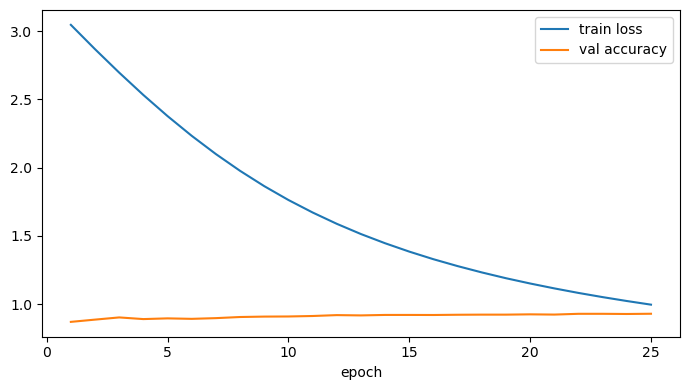

In [14]:
epochs, losses, val_accs = zip(*history)
plt.figure(figsize=(7, 4))
plt.plot(epochs, losses, label="train loss")
plt.plot(epochs, val_accs, label="val accuracy")
plt.xlabel("epoch")
plt.legend()
plt.tight_layout()
plt.show()